## 1. Setup & Daten laden



In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
df = pd.read_csv('./data/online_retail_II.csv'
#,sep=';', thousands='.', decimal=','
, parse_dates=['InvoiceDate']
#, na_values='???'
)



## 2. Daten einlesen & erste Inspektion


In [2]:
print('Zeilen, Spalten:', df.shape)
df.head()

Zeilen, Spalten: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
print(df.dtypes, "\n")
for col in df.columns:
    print(col, df[col].nunique())


Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object 

Invoice 53628
StockCode 5305
Description 5698
Quantity 1057
InvoiceDate 47635
Price 2807
Customer ID 5942
Country 43




## Änderung vom Datentyp 3er Spalten für ressourcenschonenderes Arbeiten


In [6]:
col = ['Customer ID', 'Country', 'StockCode']
df[col] = df[col].astype('category') 

In [7]:

print("=" * 80)
print("📋 DATENÜBERSICHT")
print("=" * 80)

# Grundlegende Statistiken
print(f"\n🔢 Dimensionen: {df.shape[0]:,} Zeilen × {df.shape[1]} Spalten")
print(f"🔄 Duplikate: {df.duplicated().sum():,} ({df.duplicated().sum()/len(df)*100:.2f}%)")
print(f"💾 Speichernutzung: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")



📋 DATENÜBERSICHT

🔢 Dimensionen: 1,067,371 Zeilen × 8 Spalten
🔄 Duplikate: 34,335 (3.22%)
💾 Speichernutzung: 162.70 MB


In [8]:
df.dtypes# Detaillierte Spaltenübersicht
column_info = pd.DataFrame({
    "Datentyp": df.dtypes,
    "Fehlende Werte": df.isnull().sum(),
    "Fehlend %": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Werte": df.nunique(),
    "Not a Number Werte": df.isna().sum(),
    "Beispielwerte": [df[col].dropna().sample(min(3, df[col].notna().sum())).tolist() 
                      if df[col].notna().sum() > 0 else [] 
                      for col in df.columns]
})

column_info = column_info.sort_values("Fehlend %", ascending=False)
column_info


,Datentyp,Fehlende Werte,Fehlend %,Unique Werte,Not a Number Werte,Beispielwerte
Customer ID,category,243007,22.77,5942,243007,"[13093.0, 16638.0, 13246.0]"
Description,str,4382,0.41,5698,4382,"[REGENCY CAKE SLICE, PACK OF 72 RETROSPOT CAKE..."
StockCode,category,0,0.00,5305,0,"[22629, 16237, 22699]"
Invoice,str,0,0.00,53628,0,"[546103, 492728, 546622]"
Quantity,int64,0,0.00,1057,0,"[1, 6, 12]"
InvoiceDate,datetime64[us],0,0.00,47635,0,"[2010-01-25 13:14:00, 2010-07-12 11:00:00, 201..."
Price,float64,0,0.00,2807,0,"[2.46, 8.5, 5.95]"
Country,category,0,0.00,43,0,"[United Kingdom, United Kingdom, United Kingdom]"


In [9]:

# Statistiken für numerische Spalten
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if numeric_cols:
    print(f"📊 {len(numeric_cols)} numerische Spalten gefunden\n")
    display(df[numeric_cols].describe().round(2).T)
else:
    print("⚠️ Keine numerischen Spalten gefunden")



📊 2 numerische Spalten gefunden



,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.94,172.71,-80995.00,1.00,3.0,10.00,80995.0
Price,1067371.0,4.65,123.55,-53594.36,1.25,2.1,4.15,38970.0




## Einfügen einer neuen Spalte namens "Filter". Alles unmarkierte hat erstmal eine "0". Später erhalten bestimmte Zeilen ein bestimmtes Kennzeichen zum schnellen Auffinden und Verarbeiten.

In [10]:
# 1. Erstelle die Hilfsspalte "Filter" und setze sie standardmäßig komplett auf 0
df['Filter'] = 0



## Wieviele negative Werte gibt es in den beiden numerischen Spalten "Price" und "Quantitiy" ?

In [11]:
(df[numeric_cols] < 0).sum()

Quantity    22950
Price           5
dtype: int64

In [12]:
mask = df[numeric_cols] < 0
df_m = df

In [13]:
df.duplicated().sum()

np.int64(34335)



## Löschen von Duplikaten

In [14]:
df = df.drop_duplicates()

In [15]:
df.shape

(1033036, 9)

In [16]:
#Überprüfung der Spalte Invoice auf C...  Wieviele EInträge gibt es davon?
anzahl_c = df['Invoice'].str.startswith(('c', 'C'), na=False).sum()
anzahl_c

np.int64(19104)

In [17]:
# Zählt alle Einträge, die KEINE reine Zahl sind
anzahl_keine_zahl = (~df['Invoice'].str.isnumeric()).sum()
anzahl_keine_zahl

np.int64(19110)

In [18]:
#Prüfung der C-Invoices:
# Erstellt die Bedingung (True/False-Maske)
maske_c = df['Invoice'].str.startswith(('c', 'C'), na=False)

# Filtert das DataFrame und zeigt die ersten 10 Zeilen an
df[maske_c].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,0
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,0
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,0
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,0
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,0
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,0
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,0
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,0
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,0
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,0


Scheinbar haben alle C... Invoices ein negatives Quantity. Aber es gibt 19.104 C-Invoices und 22.950 Einträge mit neg. Quantity
1. Haben alle C-Invoices einen negativen Preis?
2. Haben alle neg Quantity Einträge eine C-Invoice? Wenn nicht, wie sehen sie aus?

In [19]:
#Prüfung:  1. Haben alle C-Invoices einen negativen Preis?

# Erstelle die Maske für alle C-Rechnungen
c_maske = df['Invoice'].str.startswith(('c', 'C'), na=False)

#maske für alle Quantity >=0
mask2 = df['Quantity'] >= 0

mask_all = c_maske & mask2

print("Anzahl der C-Rechnungen mit positiver/null Menge:", mask_all.sum())


df[mask_all]

Anzahl der C-Rechnungen mit positiver/null Menge: 1


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom,0


---

## Bei der Prüfung von Retouren (C-Rechnungen) gab es einen einzelnen manuellen Datensatz ohne negative Menge, der vernachlässigbar ist.

In [20]:
# Haben alle neg Quantity Einträge eine C-Invoice? Wenn nicht, wie sehen sie aus?

#Schritt 1: alle Zeilen mit Quantity <0
mask1 = df['Quantity'] < 0
print('Anz neg Quantity in df', len(df[mask1]))

mask2 = df[mask1]['Invoice'].str.startswith(('c', 'C'), na=False)
mask = mask1 & ~mask2

print('Anz neg Quantity in df + nicht C-Invoice', len(df[mask]))

#Schreibe in all diesen Datensätzen bei Filter eine 2
df.loc[mask, 'Filter'] = 2

display(df[mask].tail())


Anz neg Quantity in df 22496
Anz neg Quantity in df + nicht C-Invoice 3393


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
1060794,581210,23395,check,-26,2011-12-07 18:36:00,0.0,NaN,United Kingdom,2
1060796,581212,22578,lost,-1050,2011-12-07 18:38:00,0.0,NaN,United Kingdom,2
1060797,581213,22576,check,-30,2011-12-07 18:38:00,0.0,NaN,United Kingdom,2
1062371,581226,23090,missing,-338,2011-12-08 09:56:00,0.0,NaN,United Kingdom,2
1064386,581422,23169,smashed,-235,2011-12-08 15:24:00,0.0,NaN,United Kingdom,2


In [21]:
list(df[mask]['Customer ID'])

[nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan



## Zusätzlich zu Kunden-Retouren (C-Rechnungen) existieren im Datensatz interne Lagerkorrekturen (z. B. für Beschädigungen oder Verluste) mit negativen Mengen und einem Preis von 0.0. Diese werden mit Filter = 2 gekennzeichnet. Somit kann man später nach Klärung diese Datensätze schnell finden und ggf. für kundenbezogene Verkaufsanalysen ausschließen (3.393 Datensätze)

In [22]:
#Alle nicht C-Invoices, die keine Zahl sind
maske_c = df['Invoice'].str.startswith(('c', 'C'), na=False)
mask_nonumber_invoice = (~df['Invoice'].str.isnumeric())

mask = ~maske_c & mask_nonumber_invoice
df.loc[mask, 'Filter'] = 1
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,1
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,1
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,1
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,1
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,1
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,1


---

## Bei der Datenbereinigung sind mir spezielle Buchungssätze aufgefallen (StockCode 'B', Beschreibung 'Adjust bad debt' mit Alphanumerischen Rechnungsnummern wie A506401). Da es sich hierbei um rein buchhalterische Abschreibungen (Bad Debt) und keine echten Kundenkäufe handelt, filtere ich diese Zeilen für die Umsatz- und Warenkorbanalyse heraus. Spalte "Filter"  wird "1" gesetzt

In [23]:
# Adjust bad debt
print('debt', df['Description'].str.contains('debt').sum())
print('B', df['StockCode'].str.contains('B').sum())
print('Adjust', df['Description'].str.contains('Adjust').sum())
print('bad', df['Description'].str.contains('bad').sum())

mask = df['Description'].str.contains('Adjust')
df[mask]

debt 6
B 35757
Adjust 79
bad 7


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
70975,495732,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:20:00,96.46,NaN,EIRE,0
70976,495733,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:21:00,68.34,14911.0,EIRE,0
70977,495735,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:22:00,201.56,12745.0,EIRE,0
70978,495734,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:22:00,205.82,14911.0,EIRE,0
70979,C495737,ADJUST,Adjustment by john on 26/01/2010 16,-1,2010-01-26 16:23:00,10.50,16154.0,United Kingdom,0
...,...,...,...,...,...,...,...,...,...
692101,550948,17109D,Adjustment,14,2011-04-21 15:56:00,0.00,NaN,United Kingdom,0
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,1
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,1
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,1




## Untersuchung der "StockCode" Spalte. Ich überprüfe hier die uniquen Werte dieser Spalte, die keine Zahlen beinhalten

In [ ]:
# Filtert alle Zeilen, deren Werte KEINE Zahlen enthalten, und holt die Uniques
df[~df['StockCode'].astype(str).str.contains(r'\d', regex=True)]['StockCode'].unique()

#r'\d', regex=True: Sucht in jedem Text nach mindestens einer Ziffer (\d steht in Regex für "digit/Zahl"). Das liefert ein True, wenn eine Zahl drin ist. Die Tilde negiert das Ergebnis, sodass wir nur die Zeilen bekommen, die KEINE Zahl enthalten.
mask = ~df['StockCode'].astype(str).str.contains(r'\d', regex=True)

testvals = df[mask]['StockCode'].unique().tolist()
#print(df[mask]['StockCode'].unique().tolist())
#print(*testvals, sep='\n')

for index, val in enumerate(testvals, start=1):
    mask = df['StockCode'] == val
    print(f'Prüfwert {index}/{len(testvals)}, {val}: {len(df[mask])} Datensätze')
    display(df[mask].head(5))
    


Prüfwert 1/17, POST: 2086 Datensätze


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.0,France,0
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA,0
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.0,Belgium,0
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.00,12533.0,Germany,0
927,C489538,POST,POSTAGE,-1,2009-12-01 12:18:00,9.58,15796.0,United Kingdom,0


Prüfwert 2/17, D: 173 Datensätze


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
735,C489535,D,Discount,-1,2009-12-01 12:11:00,9.00,15299.0,United Kingdom,0
736,C489535,D,Discount,-1,2009-12-01 12:11:00,19.00,15299.0,United Kingdom,0
24675,C491428,D,Discount,-1,2009-12-10 20:23:00,9.10,15494.0,United Kingdom,0
29414,C491845,D,Discount,-1,2009-12-14 14:54:00,1.59,NaN,United Kingdom,0
29958,C491962,D,Discount,-1,2009-12-14 16:38:00,0.59,13206.0,United Kingdom,0


Prüfwert 3/17, DOT: 1425 Datensätze


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
2379,489597,DOT,DOTCOM POSTAGE,1,2009-12-01 14:28:00,647.19,NaN,United Kingdom,0
2539,489600,DOT,DOTCOM POSTAGE,1,2009-12-01 14:43:00,55.96,NaN,United Kingdom,0
2551,489601,DOT,DOTCOM POSTAGE,1,2009-12-01 14:44:00,68.39,NaN,United Kingdom,0
2571,489602,DOT,DOTCOM POSTAGE,1,2009-12-01 14:45:00,59.35,NaN,United Kingdom,0
2619,489603,DOT,DOTCOM POSTAGE,1,2009-12-01 14:46:00,42.39,NaN,United Kingdom,0


... (24 outputs left out)

Prüfwert 16/17, AMAZONFEE: 36 Datensätze


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
440688,C531400,AMAZONFEE,AMAZON FEE,-1,2010-11-08 10:08:00,6706.71,NaN,United Kingdom,0
440698,531411,AMAZONFEE,AMAZON FEE,1,2010-11-08 10:11:00,6706.71,NaN,United Kingdom,0
517452,C537600,AMAZONFEE,AMAZON FEE,-1,2010-12-07 12:41:00,1.00,NaN,United Kingdom,0
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,0
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,0


Prüfwert 17/17, CRUK: 16 Datensätze


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
842969,C564763,CRUK,CRUK Commission,-1,2011-08-30 10:49:00,1.60,14096.0,United Kingdom,0
849464,C565382,CRUK,CRUK Commission,-1,2011-09-02 15:45:00,13.01,14096.0,United Kingdom,0
859206,C566216,CRUK,CRUK Commission,-1,2011-09-09 15:17:00,15.96,14096.0,United Kingdom,0
864273,C566565,CRUK,CRUK Commission,-1,2011-09-13 12:32:00,52.24,14096.0,United Kingdom,0
876043,C567655,CRUK,CRUK Commission,-1,2011-09-21 14:40:00,608.66,14096.0,United Kingdom,0


In [23]:
#Untersuchung aller fehlenden Werte bei Description
#alle NaNs bei Description mit kein Preis = 0
#alle NaNs bei Description mit positive Quantity:
#alle NaNs bei Description mit negative Quantity:
mask1 = df['Description'].isna()
mask_Qm = df['Quantity'] < 0
mask_Qp = df['Quantity'] > 0
mask_Q0 = df['Quantity'] == 0

mask = mask1 & mask_Qp 
print('alle NaNs bei Description mit positiver Quantity:', len(df[mask]))
mask = mask1 & mask_Qm
print('alle NaNs bei Description mit negativer Quantity:', len(df[mask]))
mask = mask1 & mask_Q0
print('alle NaNs bei Description mit Quantity = 0:', len(df[mask]))

mask_p0 = df['Price'] == 0
mask = mask1 & ~mask_p0
print('alle NaNs bei Description mit Preis = 0:', len(df[mask]))

alle NaNs bei Description mit positiver Quantity: 1642
alle NaNs bei Description mit negativer Quantity: 2633
alle NaNs bei Description mit Quantity = 0: 0
alle NaNs bei Description mit Preis = 0: 0


In [24]:
#Untersuchung der Price = 0 Datensätze
mask = df['Price'] == 0
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,2
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2
...,...,...,...,...,...,...,...,...,...
1062442,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom,0
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom,0
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom,0
1064015,581408,85175,NaN,20,2011-12-08 14:06:00,0.0,NaN,United Kingdom,0


In [335]:
df[mask]['Invoice'].unique()

<StringArray>
['489434', '489435', '489436', '489437', '489438', '489439', '489440',
 '489441', '489442', '489443',
 ...
 '581578', '581579', '581581', '581580', '581582', '581583', '581584',
 '581585', '581586', '581587']
Length: 41944, dtype: str

In [336]:
df[mask]['Customer ID'].unique()

[13,085.00, 13,078.00, 15,362.00, 18,102.00, 12,682.00, ..., 15,195.00, 13,436.00, 15,520.00, 13,298.00, 12,713.00]
Length: 5882
Categories (5942, float64): [12,346.00, 12,347.00, 12,348.00, 12,349.00, ..., 18,284.00, 18,285.00, 18,286.00, 18,287.00]

In [333]:
mask = df['Quantity'] > 0
df[mask]['Quantity'].describe()


count   1,010,540.00
mean           11.34
std           131.47
min             1.00
25%             1.00
50%             4.00
75%            12.00
max        80,995.00
Name: Quantity, dtype: float64

In [25]:
pd.options.display.float_format = '{:.2f}'.format
df['Quantity'].describe()

count   1033036.00
mean         10.08
std         175.20
min      -80995.00
25%           1.00
50%           3.00
75%          10.00
max       80995.00
Name: Quantity, dtype: float64

In [26]:
#Untersuchung der Datensätze <-1000 Mengeneinheiten und ohne Filter 2
mask1 = df['Quantity'] < -1000
mask2 = df['Filter'] <2
mask = mask1 & mask2
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
93676,C498151,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,-2504,2010-02-17 10:37:00,1.45,13902.00,Denmark,0
157466,C504415,84270,ASSTD DESIGN BUBBLE GUM RING,-1440,2010-04-13 12:33:00,0.16,12971.00,United Kingdom,0
197424,C508334,47587A,PINK FAIRY CAKE COASTER,-1200,2010-05-14 12:04:00,0.72,13694.00,United Kingdom,0
359630,C524235,16047,POP ART PEN CASE & PENS,-5184,2010-09-28 11:02:00,0.08,14277.00,France,0
359631,C524235,21280,VINTAGE KITCHEN PRINT VEGETABLES,-1248,2010-09-28 11:02:00,0.25,14277.00,France,0
359632,C524235,21281,VINTAGE KITCHEN PRINT SEAFOOD,-1536,2010-09-28 11:02:00,0.25,14277.00,France,0
359634,C524235,21392,RED POLKADOT PUDDING BOWL,-3648,2010-09-28 11:02:00,0.13,14277.00,France,0
359635,C524235,21393,BLUE POLKADOT PUDDING BOWL,-2496,2010-09-28 11:02:00,0.13,14277.00,France,0
359636,C524235,37340,MULTICOLOUR SPRING FLOWER MUG,-4992,2010-09-28 11:02:00,0.10,14277.00,France,0
359637,C524235,37423,WHITE WITH BLACK CATS PLATE,-2952,2010-09-28 11:02:00,0.10,14277.00,France,0


In [27]:
#Untersuchung der Datensätze mit Mengen über 4400
mask = df['Quantity'] > 4400
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
7303,490018,21967,PACK OF 12 SKULL TISSUES,5184,2009-12-03 12:31:00,0.25,17940.00,United Kingdom,0
65077,495194,37410,BLACK AND WHITE PAISLEY FLOWER MUG,6012,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65079,495194,16044,POP-ART FLUORESCENT PENS,6144,2010-01-21 15:11:00,0.06,13902.00,Denmark,0
65085,495194,20759,CHRYSANTHEMUM POCKET BOOK,5280,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65086,495194,20758,ABSTRACT CIRCLES POCKET BOOK,4800,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65087,495194,20757,RED DAISY POCKET BOOK,4800,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65088,495194,20756,GREEN FERN POCKET BOOK,5280,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65090,495194,20991,JAZZ HEARTS MAGNETIC MEMO PAD,6768,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
65091,495194,20993,JAZZ HEARTS MEMO PAD,9312,2010-01-21 15:11:00,0.10,13902.00,Denmark,0
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.00,Denmark,0


In [28]:
df['Price'].describe()

count   1033036.00
mean          4.61
std         122.40
min      -53594.36
25%           1.25
50%           2.10
75%           4.15
max       38970.00
Name: Price, dtype: float64

In [29]:
#Untersuchung der Datensätze mit negativen Preis 
mask = df['Price'] < 0
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,1
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,1
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,1
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,1
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,1


In [30]:
#Untersuchung der Datensätze mit Preis über 10000 
mask = df['Price'] > 10000
df[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter
135012,C502262,M,Manual,-1,2010-03-23 15:20:00,10953.50,12918.00,United Kingdom,0
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.00,United Kingdom,0
135014,C502264,M,Manual,-1,2010-03-23 15:24:00,10953.50,12918.00,United Kingdom,0
135015,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,0
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.00,United Kingdom,0
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,0
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,0
342135,C522793,M,Manual,-1,2010-09-16 14:53:00,10468.80,14063.00,United Kingdom,0
342147,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,NaN,United Kingdom,0
358639,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,14063.00,United Kingdom,0


In [31]:
# Prüft, ob der Rest ungleich 0 ist und schließt NaN-Werte (Lücken) sicher aus

anzahl_mit_nachkomma = (df['Customer ID'].astype('float') % 1 != 0)

print(f"Anzahl Werte mit Nachkommastellen: {anzahl_mit_nachkomma}")

    


Anzahl Werte mit Nachkommastellen: 0          False
1          False
2          False
3          False
4          False
           ...  
1067366    False
1067367    False
1067368    False
1067369    False
1067370    False
Name: Customer ID, Length: 1033036, dtype: bool


In [49]:
var_cross_tab = pd.crosstab(index=df.loc[:, 'Customer ID'], 
            columns='Quantity',
            values=df.loc[:, 'Quantity'],##die zeile ist imho optional
            aggfunc='sum').sort_values(by='Quantity', ascending=False) #die zeile ist imho optional

In [51]:
var_cross_tab

col_0,Quantity
Customer ID,
14646.00,365220
13902.00,218090
13694.00,184534
18102.00,180415
14156.00,162245
...,...
17755.00,-30
15767.00,-50
15935.00,-171


In [53]:
mask = df['Customer ID'] == 14646
df2 = df[mask]
pd.crosstab(index=df2.loc[:, 'Customer ID'], 
            columns='Quantity',
            values=df2.loc[:, 'Quantity'],##die zeile ist imho optional
            aggfunc='sum').sort_values(by='Quantity', ascending=False) #die zeile ist imho optional


col_0,Quantity
Customer ID,
14646.00,365220


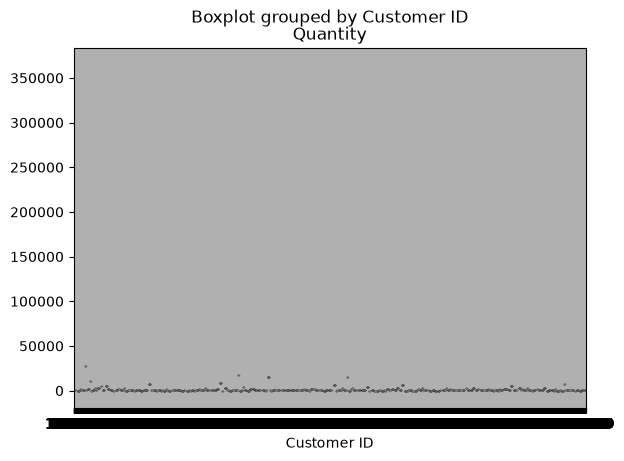

In [50]:
var_cross_tab.boxplot(column='Quantity', by='Customer ID', showfliers=True) ;

In [37]:
df.to_csv('online_retail_II-clean.csv')  

In [56]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter,total_pice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom,0,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,0,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom,0,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom,0,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom,0,30.00


In [55]:
df['total_pice'] = df['Quantity'] * df['Price']

In [57]:
mask = df['total_pice'] > 0
df3 = df[mask]

In [356]:
df[mask]['Invoice'].unique()

<StringArray>
['489434', '489435', '489436', '489437', '489438', '489439', '489440',
 '489441', '489442', '489443',
 ...
 '581578', '581579', '581581', '581580', '581582', '581583', '581584',
 '581585', '581586', '581587']
Length: 41944, dtype: str

In [357]:
df3['Invoice'].unique()

<StringArray>
['489434', '489435', '489436', '489437', '489438', '489439', '489440',
 '489441', '489442', '489443',
 ...
 '581578', '581579', '581581', '581580', '581582', '581583', '581584',
 '581585', '581586', '581587']
Length: 40078, dtype: str

In [204]:
mask = df3['Customer ID'] == 12350
df3[mask]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Filter,total_pice
605784,543037,21908,CHOCOLATE THIS WAY METAL SIGN,12,2011-02-02 16:01:00,2.10,"12,350.00",Norway,0,25.20
605785,543037,22412,METAL SIGN NEIGHBOURHOOD WITCH,12,2011-02-02 16:01:00,2.10,"12,350.00",Norway,0,25.20
605786,543037,79066K,RETRO MOD TRAY,10,2011-02-02 16:01:00,0.85,"12,350.00",Norway,0,8.50
605787,543037,79191C,RETRO PLASTIC ELEPHANT TRAY,12,2011-02-02 16:01:00,0.85,"12,350.00",Norway,0,10.20
605788,543037,22348,TEA BAG PLATE RED RETROSPOT,24,2011-02-02 16:01:00,0.85,"12,350.00",Norway,0,20.40
605789,543037,84086C,PINK/PURPLE RETRO RADIO,6,2011-02-02 16:01:00,2.95,"12,350.00",Norway,0,17.70
605790,543037,22551,PLASTERS IN TIN SPACEBOY,12,2011-02-02 16:01:00,1.65,"12,350.00",Norway,0,19.80
605791,543037,22557,PLASTERS IN TIN VINTAGE PAISLEY,12,2011-02-02 16:01:00,1.65,"12,350.00",Norway,0,19.80
605792,543037,21832,CHOCOLATE CALCULATOR,12,2011-02-02 16:01:00,1.65,"12,350.00",Norway,0,19.80
605793,543037,21915,RED HARMONICA IN BOX,12,2011-02-02 16:01:00,1.25,"12,350.00",Norway,0,15.00


In [208]:
df3[mask].('total_pice').sum()

SyntaxError: invalid syntax (1505123034.py, line 1)

In [78]:
df3b = df3.iloc[:,[0, 4, 6]]

In [79]:
df3b.head()

,Invoice,InvoiceDate,Customer ID
0,489434,2009-12-01 07:45:00,13085.00
1,489434,2009-12-01 07:45:00,13085.00
2,489434,2009-12-01 07:45:00,13085.00
3,489434,2009-12-01 07:45:00,13085.00
4,489434,2009-12-01 07:45:00,13085.00


In [82]:
df3b.shape

(1007914, 3)

In [85]:
df3b = df3b.drop_duplicates()

In [86]:
df3b

,Invoice,InvoiceDate,Customer ID
0,489434,2009-12-01 07:45:00,13085.00
8,489435,2009-12-01 07:46:00,13085.00
12,489436,2009-12-01 09:06:00,13078.00
31,489437,2009-12-01 09:08:00,15362.00
54,489438,2009-12-01 09:24:00,18102.00
...,...,...,...
1067326,581583,2011-12-09 12:23:00,13777.00
1067328,581584,2011-12-09 12:25:00,13777.00
1067330,581585,2011-12-09 12:31:00,15804.00
1067351,581586,2011-12-09 12:49:00,13113.00


In [87]:
crosstab = pd.crosstab(index=df3.loc[:, 'Invoice'], 
            columns='summe',
            values=df3.loc[:, 'total_pice']
            ,aggfunc='sum'
            ) 
df4 = crosstab.merge(right = df3b, how = 'inner', on = 'Invoice')
df4.head()

,Invoice,summe,InvoiceDate,Customer ID
0,489434,505.30,2009-12-01 07:45:00,13085.00
1,489435,145.80,2009-12-01 07:46:00,13085.00
2,489436,630.33,2009-12-01 09:06:00,13078.00
3,489437,310.75,2009-12-01 09:08:00,15362.00
4,489438,2286.24,2009-12-01 09:24:00,18102.00


In [352]:
df4.head()

,Invoice,summe,InvoiceDate,Customer ID
0,489434,505.30,2009-12-01 07:45:00,"13,085.00"
1,489435,145.80,2009-12-01 07:46:00,"13,085.00"
2,489436,630.33,2009-12-01 09:06:00,"13,078.00"
3,489437,310.75,2009-12-01 09:08:00,"15,362.00"
4,489438,"2,286.24",2009-12-01 09:24:00,"18,102.00"


In [347]:
df4s.head(13)


,Invoice,summe,InvoiceDate,Customer ID,order_time,order_num,total_orders
1082,491725,45.00,2009-12-14 08:34:00,"12,346.00",NaT,1.00,12.00
1093,491742,22.50,2009-12-14 11:00:00,"12,346.00",0 days 02:26:00,2.00,12.00
1095,491744,22.50,2009-12-14 11:02:00,"12,346.00",0 days 00:02:00,3.00,12.00
1479,492718,22.50,2009-12-18 10:47:00,"12,346.00",3 days 23:45:00,4.00,12.00
1481,492722,1.00,2009-12-18 10:55:00,"12,346.00",0 days 00:08:00,5.00,12.00
1683,493410,22.50,2010-01-04 09:24:00,"12,346.00",16 days 22:29:00,6.00,12.00
1684,493412,22.50,2010-01-04 09:53:00,"12,346.00",0 days 00:29:00,7.00,12.00
2041,494450,22.50,2010-01-14 13:50:00,"12,346.00",10 days 03:57:00,8.00,12.00
2355,495295,22.50,2010-01-22 13:30:00,"12,346.00",7 days 23:40:00,9.00,12.00
4069,499763,27.05,2010-03-02 13:08:00,"12,346.00",38 days 23:38:00,10.00,12.00


In [198]:
print(df4s.groupby('Customer ID')['InvoiceDate'].count())

Customer ID
12,346.00    12
12,347.00     8
12,348.00     5
12,349.00     4
12,350.00     1
             ..
18,283.00    22
18,284.00     1
18,285.00     1
18,286.00     2
18,287.00     7
Name: InvoiceDate, Length: 5878, dtype: int64


In [ ]:
# order_time Berechnung pro Kunde
df4s['order_time'] = df4s['InvoiceDate'] - df4s.groupby('Customer ID')['InvoiceDate'].shift(1)
df4s.head(13)


,Invoice,summe,InvoiceDate,Customer ID,order_time
1082,491725,45.00,2009-12-14 08:34:00,12346.00,NaT
1093,491742,22.50,2009-12-14 11:00:00,12346.00,0 days 02:26:00
1095,491744,22.50,2009-12-14 11:02:00,12346.00,0 days 00:02:00
1479,492718,22.50,2009-12-18 10:47:00,12346.00,3 days 23:45:00
1481,492722,1.00,2009-12-18 10:55:00,12346.00,0 days 00:08:00
1683,493410,22.50,2010-01-04 09:24:00,12346.00,16 days 22:29:00
1684,493412,22.50,2010-01-04 09:53:00,12346.00,0 days 00:29:00
2041,494450,22.50,2010-01-14 13:50:00,12346.00,10 days 03:57:00
2355,495295,22.50,2010-01-22 13:30:00,12346.00,7 days 23:40:00
4069,499763,27.05,2010-03-02 13:08:00,12346.00,38 days 23:38:00


In [196]:
df4s.groupby('Customer ID')['summe'].sum()

Customer ID
12,346.00   77,556.46
12,347.00    4,921.53
12,348.00    2,019.40
12,349.00    4,428.69
12,350.00      334.40
               ...   
18,283.00    2,664.90
18,284.00      461.68
18,285.00      427.00
18,286.00    1,296.43
18,287.00    4,182.99
Name: summe, Length: 5878, dtype: float64

In [340]:
df4['Invoice'].count()  

np.int64(40160)

In [341]:
df4['Customer ID'].count()

np.int64(37033)

In [238]:
# -------------------------------------------------------------------------
# SCHRITT 1: Hilfsspalten für die Hälften-Berechnung anlegen
# -------------------------------------------------------------------------
# 1. Fortlaufende Nummer pro Bestellung (1, 2, 3...)
df4s['order_num'] = df4s.groupby('Customer ID').cumcount() + 1

# 2. Gesamtanzahl an Bestellungen pro Kunde
df4s['total_orders'] = df4s.groupby('Customer ID')['Invoice'].transform('count')


# -------------------------------------------------------------------------
# SCHRITT 2: Berechnungen durchführen
# -------------------------------------------------------------------------
# a) Gesamtdurchschnitt der Zeitabstände
avg_all = df4s.groupby('Customer ID')['order_time'].mean()

# b) Durchschnitt der ersten Hälfte
# Maske: Laufende Nummer ist kleiner/gleich der halben Gesamtanzahl
mask_first_half = df4s['order_num'] <= (df4s['total_orders'] / 2)
avg_first_half = df4s[mask_first_half].groupby('Customer ID')['order_time'].mean()

# c) Durchschnitt der zweiten Hälfte
mask_second_half = df4s['order_num'] > (df4s['total_orders'] / 2)
avg_second_half = df4s[mask_second_half].groupby('Customer ID')['order_time'].mean()

# d) Zeit seit der letzten Bestellung
# Referenzwert: Der allerletzte Tag, der im gesamten Datensatz vorkommt
max_date = df4s['InvoiceDate'].max()
# Letztes Kaufdatum pro Kunde
last_order_dates = df4s.groupby('Customer ID')['InvoiceDate'].max()
time_since_last_order = max_date - last_order_dates


# -------------------------------------------------------------------------
# SCHRITT 3: Alles in einer sauberen, neuen Tabelle zusammenführen
# -------------------------------------------------------------------------
# Wir bauen einen neuen DataFrame direkt aus den berechneten Serien.
# Da alle Serien nach 'Customer ID' gruppiert wurden, passen sie perfekt zusammen!
kunden_kpi = pd.DataFrame({
    'avg_order_time': avg_all,
    'avg_first_half': avg_first_half,
    'avg_second_half': avg_second_half,
    'time_since_last_order': time_since_last_order,
    'total_orders': df4s.groupby('Customer ID')['Invoice'].count(), # optional, aber gut zur Kontrolle
    'total_sum' : df4s.groupby('Customer ID')['summe'].sum()
})

# Den Index (die Customer ID) wieder als normale Spalte zurückholen
#kunden_kpi = kunden_kpi.reset_index()

# Fertig! Lass dir das Ergebnis anzeigen:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum
Customer ID,,,,,,
"12,346.00",36 days 08:51:32.727272,4 days 04:58:00,63 days 04:06:10,325 days 02:49:00,12,"77,556.46"
"12,347.00",57 days 10:30:17.142857,52 days 14:47:40,61 days 01:17:15,1 days 20:58:00,8,"4,921.53"
"12,348.00",90 days 17:33:30,80 days 04:10:00,94 days 06:01:20,74 days 23:37:00,5,"2,019.40"
"12,349.00",190 days 06:50:20,18 days 20:37:00,275 days 23:57:00,18 days 02:59:00,4,"4,428.69"
"12,350.00",NaT,NaT,NaT,309 days 20:49:00,1,334.40


In [277]:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Bestellrhythmus_Trend,Frequency,Monetary_Value,RFM_Score
Customer ID,,,,,,,,,,,
"12,346.00",36 days 08:51:32.727272,4 days 04:58:00,63 days 04:06:10,325 days 02:49:00,12,"77,556.46",15.02,1,6,10,17
"12,347.00",57 days 10:30:17.142857,52 days 14:47:40,61 days 01:17:15,1 days 20:58:00,8,"4,921.53",1.16,5,5,9,19
"12,348.00",90 days 17:33:30,80 days 04:10:00,94 days 06:01:20,74 days 23:37:00,5,"2,019.40",1.18,0,3,8,11
"12,349.00",190 days 06:50:20,18 days 20:37:00,275 days 23:57:00,18 days 02:59:00,4,"4,428.69",14.63,0,3,9,12
"12,350.00",NaT,NaT,NaT,309 days 20:49:00,1,334.40,NaN,0,0,3,3


In [275]:
# Benennt die Spalte "Recency" in "Neue_Ueberschrift" um
kunden_kpi = kunden_kpi.rename(columns={'Recency': 'Bestellrhythmus_Trend'})

In [276]:
kunden_kpi.shape

(5878, 11)

In [274]:
np.isinf(kunden_kpi['avg_incr']).sum()

np.int64(2)

In [239]:
kunden_kpi['avg_incr'] = kunden_kpi['avg_second_half'] / kunden_kpi['avg_first_half']

In [240]:
mask = kunden_kpi['total_orders'] >= 8

In [192]:
kunden_kpi[mask]['avg_incr'].describe()

count    1,303.00
mean        10.79
std        317.20
min          0.04
25%          0.80
50%          1.15
75%          1.74
max     11,446.11
Name: avg_incr, dtype: float64

In [ ]:
perzentil_schwellenwerte = []
for i in [10, 20, 30, 40, 50, 60, 70, 80, 90]:
    perzentil_schwellenwerte.append(np.percentile(kunden_kpi[mask]['avg_incr'], i))

perzentil_schwellenwerte

[np.float64(0.491204324697296),
 np.float64(0.7218887450563141),
 np.float64(0.8553892720790882),
 np.float64(0.9974324634047833),
 np.float64(1.1496243647594477),
 np.float64(1.3242817221711602),
 np.float64(1.565418994787635),
 np.float64(1.918471097061844),
 np.float64(2.7220075966246458)]

In [ ]:
# 1. Bedingungen definieren:
conditions = [
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[0],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[1],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[2],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[3],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[4],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[5],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[6],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[7],  
    kunden_kpi[mask]['avg_incr'] < perzentil_schwellenwerte[8],  
    kunden_kpi[mask]['avg_incr'] >= perzentil_schwellenwerte[8]  
   ]

# 2. Werte definieren, die zugewiesen werden sollen
choices = [10, 9, 8, 7, 6, 5, 4, 3, 2, 1]  # Zugehörige Zielwerte

# 3. Neue Spalte erstellen
kunden_kpi.loc[mask, 'Bestellrhythmus_Trend'] = np.select(conditions, choices, default=9)

In [318]:
np.isinf(kunden_kpi['avg_incr']).sum()



np.int64(0)

In [315]:
kunden_kpi[mask]

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Bestellrhythmus_Trend,Recency,Frequency,Monetary_Value,RFM_Score
Customer ID,,,,,,,,,,,,
"12,906.00",16.00,0.00,22.00,11,5,"2,919.81",0.00,0,9,3,8,20
"12,920.00",235.00,0.00,353.00,16,4,486.64,0.00,0,9,3,4,16


In [314]:
kunden_kpi.loc[mask, 'avg_incr'] = 0

In [243]:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Recency
Customer ID,,,,,,,,
"12,346.00",36 days 08:51:32.727272,4 days 04:58:00,63 days 04:06:10,325 days 02:49:00,12,"77,556.46",15.02,1.00
"12,347.00",57 days 10:30:17.142857,52 days 14:47:40,61 days 01:17:15,1 days 20:58:00,8,"4,921.53",1.16,5.00
"12,348.00",90 days 17:33:30,80 days 04:10:00,94 days 06:01:20,74 days 23:37:00,5,"2,019.40",1.18,NaN
"12,349.00",190 days 06:50:20,18 days 20:37:00,275 days 23:57:00,18 days 02:59:00,4,"4,428.69",14.63,NaN
"12,350.00",NaT,NaT,NaT,309 days 20:49:00,1,334.40,NaN,NaN


In [244]:
#Perzentil 10er gruppierungen für total orders für die anschließende Klassifizierung
perzentil_schwellenwerte = []
for i in [10, 20, 30, 40, 50, 60, 70, 80, 90]:
    perzentil_schwellenwerte.append(np.percentile(kunden_kpi['total_orders'], i))
    print(i/10, np.percentile(kunden_kpi['total_orders'], i))

perzentil_schwellenwerte

1.0 1.0
2.0 1.0
3.0 2.0
4.0 2.0
5.0 3.0
6.0 4.0
7.0 6.0
8.0 8.0
9.0 13.0


[np.float64(1.0),
 np.float64(1.0),
 np.float64(2.0),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(4.0),
 np.float64(6.0),
 np.float64(8.0),
 np.float64(13.0)]

In [342]:
kunden_kpi['total_orders'].describe()

count   5,878.00
mean        6.30
std        13.04
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       400.00
Name: total_orders, dtype: float64

In [344]:
kunden_kpi['total_orders'].sum()

np.int64(37033)

In [346]:
37033 / 5878

6.300272201429057

In [220]:
perzentil_schwellenwerte[8]

np.float64(13.0)

In [231]:
list(range(1, 11))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [248]:
# 1. Bedingungen definieren:
conditions = [
    kunden_kpi['total_orders'] <= 1,  #0 Punkte
    kunden_kpi['total_orders'] == 2,  #1 Punkte
    kunden_kpi['total_orders'] == 3,  #2 Punkte 
    kunden_kpi['total_orders'] <= 5,  #3 Punkte
    kunden_kpi['total_orders'] <= 7,  #4 Punkte
    kunden_kpi['total_orders'] <= 9,  #5 Punkte
    kunden_kpi['total_orders'] <= 12, #6 Punkte
    kunden_kpi['total_orders'] <  25, #7 Punkte
    kunden_kpi['total_orders'] <  50, #8 Punkte
    kunden_kpi['total_orders'] < 100, #9 Punkte
    kunden_kpi['total_orders'] >= 100, #10 Punkte
   ]

# 2. Werte definieren, die zugewiesen werden sollen
choices = list(range(0, 11))  # Zugehörige Zielwerte

# 3. Neue Spalte erstellen
kunden_kpi.loc[:, 'Frequency'] = np.select(conditions, choices, default=9)

In [257]:
kunden_kpi['Recency'] = kunden_kpi['Recency'].fillna(0)
kunden_kpi['Recency'] = kunden_kpi['Recency'].astype('int')

In [259]:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Recency,Frequency
Customer ID,,,,,,,,,
"12,346.00",36 days 08:51:32.727272,4 days 04:58:00,63 days 04:06:10,325 days 02:49:00,12,"77,556.46",15.02,1,6
"12,347.00",57 days 10:30:17.142857,52 days 14:47:40,61 days 01:17:15,1 days 20:58:00,8,"4,921.53",1.16,5,5
"12,348.00",90 days 17:33:30,80 days 04:10:00,94 days 06:01:20,74 days 23:37:00,5,"2,019.40",1.18,0,3
"12,349.00",190 days 06:50:20,18 days 20:37:00,275 days 23:57:00,18 days 02:59:00,4,"4,428.69",14.63,0,3
"12,350.00",NaT,NaT,NaT,309 days 20:49:00,1,334.40,NaN,0,0


In [262]:
kunden_kpi['total_sum'].describe()

count     5,878.00
mean      2,962.21
std      14,458.33
min           2.95
25%         342.48
50%         869.14
75%       2,255.22
max     580,987.04
Name: total_sum, dtype: float64

In [261]:
#Perzentil 10er gruppierungen für total_sum für die anschließende Klassifizierung
perzentil_schwellenwerte = []
for i in [10, 20, 30, 40, 50, 60, 70, 80, 90]:
    perzentil_schwellenwerte.append(np.percentile(kunden_kpi['total_sum'], i))
    print(i/10, np.percentile(kunden_kpi['total_sum'], i))

perzentil_schwellenwerte

1.0 161.58300000000003
2.0 285.656
3.0 409.111
4.0 609.882
5.0 869.14
6.0 1222.8119999999997
7.0 1818.571
8.0 2929.066000000001
9.0 5470.424000000002


[np.float64(161.58300000000003),
 np.float64(285.656),
 np.float64(409.111),
 np.float64(609.882),
 np.float64(869.14),
 np.float64(1222.8119999999997),
 np.float64(1818.571),
 np.float64(2929.066000000001),
 np.float64(5470.424000000002)]

In [266]:
# 1. Bedingungen definieren:
conditions = [
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[0],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[1],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[2],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[3],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[4],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[5],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[6],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[7],  
    kunden_kpi['total_sum'] < perzentil_schwellenwerte[8],  
    kunden_kpi['total_sum'] >= perzentil_schwellenwerte[8]  
   ]

# 2. Werte definieren, die zugewiesen werden sollen
choices = list(range(1, 11))  # Zugehörige Zielwerte

# 3. Neue Spalte erstellen
kunden_kpi.loc[:, 'Monetary_Value'] = np.select(conditions, choices, default=9)

In [304]:
kunden_kpi['RFM_Score'] = kunden_kpi['Recency'] + kunden_kpi['Frequency'] + kunden_kpi['Monetary_Value']

In [291]:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Bestellrhythmus_Trend,Frequency,Monetary_Value,RFM_Score
Customer ID,,,,,,,,,,,
"12,346.00",36.00,4.00,63.00,325,12,"77,556.46",15.02,1,6,10,17
"12,347.00",57.00,52.00,61.00,1,8,"4,921.53",1.16,5,5,9,19
"12,348.00",90.00,80.00,94.00,74,5,"2,019.40",1.18,0,3,8,11
"12,349.00",190.00,18.00,275.00,18,4,"4,428.69",14.63,0,3,9,12
"12,350.00",NaN,NaN,NaN,309,1,334.40,NaN,0,0,3,3


In [292]:
#Perzentil 10er gruppierungen für time_since_last_order für die anschließende Klassifizierung
perzentil_schwellenwerte = []
for i in [10, 20, 30, 40, 50, 60, 70, 80, 90]:
    perzentil_schwellenwerte.append(np.percentile(kunden_kpi['time_since_last_order'], i))
    print(i/10, np.percentile(kunden_kpi['time_since_last_order'], i))

perzentil_schwellenwerte

1.0 8.0
2.0 18.0
3.0 32.0
4.0 58.0
5.0 95.0
6.0 188.0
7.0 310.0
8.0 409.0
9.0 534.0


[np.float64(8.0),
 np.float64(18.0),
 np.float64(32.0),
 np.float64(58.0),
 np.float64(95.0),
 np.float64(188.0),
 np.float64(310.0),
 np.float64(409.0),
 np.float64(534.0)]

In [300]:
# 1. Bedingungen definieren:
conditions = [
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[0],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[1],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[2],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[3],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[4],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[5],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[6],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[7],  
    kunden_kpi['time_since_last_order'] <= perzentil_schwellenwerte[8],  
    kunden_kpi['time_since_last_order'] > perzentil_schwellenwerte[8]  
   ]

# 2. Werte definieren, die zugewiesen werden sollen
choices = list(range(10, 0, -1))  # Zugehörige Zielwerte

# 3. Neue Spalte erstellen
kunden_kpi.loc[:, 'Recency'] = np.select(conditions, choices, default=9)

In [302]:
# 1. Alle Spalten als Liste holen
cols = list(kunden_kpi.columns)

# 2. 'Recency' aus der Liste entfernen, falls es drin ist
cols.remove('Recency')

# 3. Den Index herausfinden, wo 'Bestellrhythmus_Trend' steht, 
# damit wir 'Recency' direkt dahinter setzen können
idx = cols.index('Bestellrhythmus_Trend') + 1

# 4. 'Recency' an genau dieser neuen Position einfügen
cols.insert(idx, 'Recency')

# 5. Dem DataFrame die neue Spaltenreihenfolge zuweisen
kunden_kpi = kunden_kpi[cols]

In [320]:
kunden_kpi.head()

,avg_order_time,avg_first_half,avg_second_half,time_since_last_order,total_orders,total_sum,avg_incr,Bestellrhythmus_Trend,Recency,Frequency,Monetary_Value,RFM_Score
Customer ID,,,,,,,,,,,,
"12,346.00",36.00,4.00,63.00,325,12,"77,556.46",15.02,1,3,6,10,19
"12,347.00",57.00,52.00,61.00,1,8,"4,921.53",1.16,5,10,5,9,24
"12,348.00",90.00,80.00,94.00,74,5,"2,019.40",1.18,0,6,3,8,17
"12,349.00",190.00,18.00,275.00,18,4,"4,428.69",14.63,0,9,3,9,21
"12,350.00",NaN,NaN,NaN,309,1,334.40,NaN,0,4,0,3,7


In [321]:
kunden_kpi['total_sum'].sum()

np.float64(17411883.788)

In [323]:
kunden_kpi['total_sum'].describe()

count     5,878.00
mean      2,962.21
std      14,458.33
min           2.95
25%         342.48
50%         869.14
75%       2,255.22
max     580,987.04
Name: total_sum, dtype: float64

In [290]:
# Liste der Spalten, die du umwandeln möchtest
spalten_zum_umwandeln = [
    'avg_order_time',
    'avg_first_half',
    'avg_second_half',
    'time_since_last_order',
]

# Schleife über die Spaltennamen
for spalte in spalten_zum_umwandeln:
  kunden_kpi[spalte] = kunden_kpi[spalte].dt.days

In [319]:
kunden_kpi.to_csv('online_retail_II-kpi2.csv')  

In [326]:
kunden_kpi['total_orders'].describe()

count   5,878.00
mean        6.30
std        13.04
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       400.00
Name: total_orders, dtype: float64